# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from pathlib import Path
import joblib
import json

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    ConfusionMatrixDisplay, 
    roc_auc_score, 
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

# Load Dataset & Replicate Split Strategy

In [2]:
PROJECT_ROOT = Path(".").resolve().parent 

DATA_DIR   = PROJECT_ROOT / "Data"  
ASSET_DIR  = PROJECT_ROOT / "Assets" 
MODEL_DIR  = PROJECT_ROOT / "Models" 

ASSET_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

df1 = pd.read_csv(DATA_DIR / "diabetes_012_health_indicators_BRFSS2015_BRFSS2021.csv")

x_df1 = df1[['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker',
             'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
             'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
             'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']]

y_df1 = df1["Health_Status"]

xtrain_val_df1, xtest_df1, ytrain_val_df1, ytest_df1 = train_test_split(
    x_df1, y_df1, test_size=0.20, random_state=42, shuffle=True, stratify=y_df1
)

xtrain_df1, xval_df1, ytrain_df1, yval_df1 = train_test_split(
    xtrain_val_df1, ytrain_val_df1, test_size=0.20, random_state=42, shuffle=True, stratify=ytrain_val_df1
)

print(f"Train shape: {xtrain_df1.shape}   Validation shape: {xval_df1.shape}   Test shape: {xtest_df1.shape}")

Train shape: (290131, 21)   Validation shape: (72533, 21)   Test shape: (90667, 21)


# Part 1: Train XGBoost Classifier
## Train XGBoost Classifier with Imbalance Handling

In [3]:
class_counts = ytrain_df1.value_counts()
scale_pos_weight_val = class_counts.loc[0] / class_counts.loc[1]

print(f"Majority (Healthy): {class_counts.loc[0]} | Minority (At Risk): {class_counts.loc[1]}")
print(f"Computed scale_pos_weight: {scale_pos_weight_val:.4f}")

xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    scale_pos_weight=scale_pos_weight_val,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    xtrain_df1, 
    ytrain_df1,
    eval_set=[(xval_df1, yval_df1)],
    verbose=20
)

Majority (Healthy): 239741 | Minority (At Risk): 50390
Computed scale_pos_weight: 4.7577
[0]	validation_0-logloss:0.68067
[20]	validation_0-logloss:0.57233
[40]	validation_0-logloss:0.54808
[60]	validation_0-logloss:0.54028
[80]	validation_0-logloss:0.53719
[100]	validation_0-logloss:0.53561
[120]	validation_0-logloss:0.53469
[140]	validation_0-logloss:0.53409
[160]	validation_0-logloss:0.53361
[180]	validation_0-logloss:0.53324
[199]	validation_0-logloss:0.53295


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


# Evaluate and Plot Confusion Matrix

              precision    recall  f1-score   support

     Healthy       0.93      0.70      0.80     74920
     At Risk       0.35      0.76      0.48     15747

    accuracy                           0.71     90667
   macro avg       0.64      0.73      0.64     90667
weighted avg       0.83      0.71      0.74     90667

[[52326 22594]
 [ 3738 12009]]


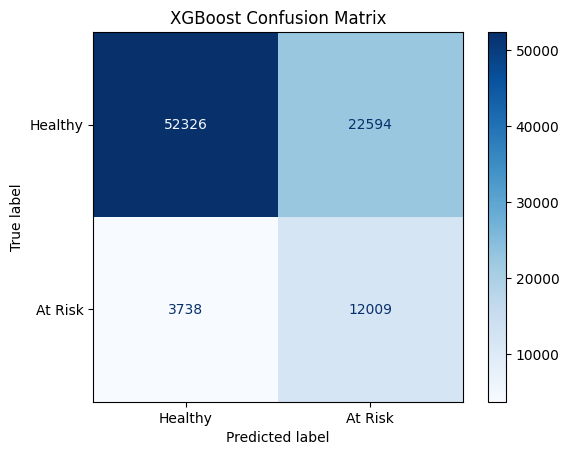

In [4]:
y_prob_xgb = xgb_model.predict_proba(xtest_df1)[:, 1]
y_pred_xgb = (y_prob_xgb >= 0.5).astype(int)

print(classification_report(
    ytest_df1,
    y_pred_xgb,
    target_names=["Healthy", "At Risk"],
    zero_division=0
))

cm = confusion_matrix(ytest_df1, y_pred_xgb)
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy", "At Risk"]
).plot(cmap=plt.cm.Blues)

plt.title("XGBoost Confusion Matrix")
plt.savefig(ASSET_DIR / "confusion_matrix_xgb.png", dpi=300, bbox_inches="tight")
plt.show()

# ROC-AUC Score and Probability Threshold Tuning

In [5]:
auc_score = roc_auc_score(ytest_df1, y_prob_xgb)
print(f"XGBoost Test ROC-AUC Score: {auc_score:.4f}")


# threshold = .60 here not .50 
custom_threshold = 0.60
y_pred_custom = (y_prob_xgb > custom_threshold).astype(int)

print(f"\nEvaluation with Custom Threshold ({custom_threshold}):")
print(classification_report(
    ytest_df1,
    y_pred_custom,
    target_names=["Healthy", "At Risk"],
    zero_division=0
))

XGBoost Test ROC-AUC Score: 0.8058

Evaluation with Custom Threshold (0.6):
              precision    recall  f1-score   support

     Healthy       0.91      0.80      0.85     74920
     At Risk       0.40      0.64      0.49     15747

    accuracy                           0.77     90667
   macro avg       0.66      0.72      0.67     90667
weighted avg       0.82      0.77      0.79     90667



# Save Model and Evaluation Metrics

In [6]:
eval_metrics = classification_report(
    ytest_df1, y_pred_xgb, target_names=["Healthy", "At Risk"], output_dict=True
)

eval_path = MODEL_DIR / "model_xgb_evaluations.json"
with open(eval_path, "w") as f:
    json.dump(eval_metrics, f, indent=4)

# Save the trained XGBoost model using joblib
model_path = MODEL_DIR / "xgb_model.pkl"
joblib.dump(xgb_model, model_path)

print(f"Model saved successfully to {model_path}")
print(f"Metrics saved successfully to {eval_path}")

Model saved successfully to D:\ANN- health-risk-prediction-project\Models\xgb_model.pkl
Metrics saved successfully to D:\ANN- health-risk-prediction-project\Models\model_xgb_evaluations.json


# Part 2: Train CatBoost Classifier

In [7]:
cat_model = CatBoostClassifier(
    iterations=300,
    learning_rate=0.05,
    depth=6,
    auto_class_weights='Balanced',
    random_seed=42,
    verbose=50
)

cat_model.fit(
    xtrain_df1, 
    ytrain_df1,
    eval_set=(xval_df1, yval_df1),
    early_stopping_rounds=30
)

0:	learn: 0.6779389	test: 0.6779364	best: 0.6779364 (0)	total: 169ms	remaining: 50.5s
50:	learn: 0.5376093	test: 0.5378340	best: 0.5378340 (50)	total: 1.78s	remaining: 8.71s
100:	learn: 0.5309323	test: 0.5317546	best: 0.5317546 (100)	total: 3.33s	remaining: 6.57s
150:	learn: 0.5286871	test: 0.5302857	best: 0.5302857 (150)	total: 4.97s	remaining: 4.91s
200:	learn: 0.5272534	test: 0.5295902	best: 0.5295902 (200)	total: 6.57s	remaining: 3.23s
250:	learn: 0.5260698	test: 0.5291431	best: 0.5291431 (250)	total: 8.18s	remaining: 1.6s
299:	learn: 0.5249095	test: 0.5288552	best: 0.5288552 (299)	total: 9.8s	remaining: 0us

bestTest = 0.5288551928
bestIteration = 299



CatBoostClassifier(auto_class_weights='Balanced', depth=6, iterations=300, learning_rate=0.05, random_seed=42, verbose=50)

# Evaluate CatBoost and Save Artifacts

--- CatBoost Classification Report ---
              precision    recall  f1-score   support

     Healthy       0.93      0.70      0.80     74920
     At Risk       0.35      0.76      0.48     15747

    accuracy                           0.71     90667
   macro avg       0.64      0.73      0.64     90667
weighted avg       0.83      0.71      0.74     90667



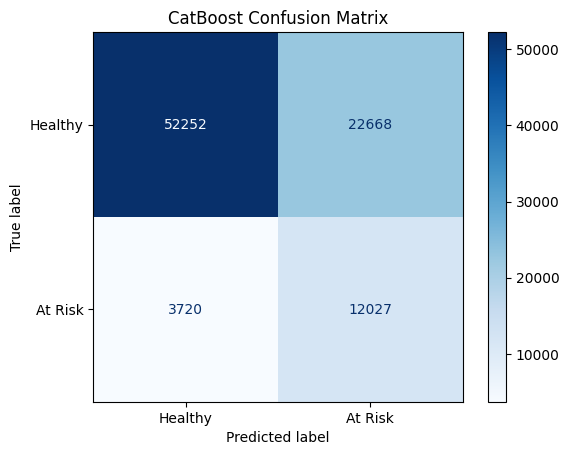

CatBoost ROC-AUC Score: 0.8065


In [8]:
y_prob_cat = cat_model.predict_proba(xtest_df1)[:, 1]
y_pred_cat = (y_prob_cat >= 0.5).astype(int)

print("--- CatBoost Classification Report ---")
print(classification_report(
    ytest_df1,
    y_pred_cat,
    target_names=["Healthy", "At Risk"],
    zero_division=0
))

cm_cat = confusion_matrix(ytest_df1, y_pred_cat)
ConfusionMatrixDisplay(
    confusion_matrix=cm_cat,
    display_labels=["Healthy", "At Risk"]
).plot(cmap=plt.cm.Blues)

plt.title("CatBoost Confusion Matrix")
plt.savefig(ASSET_DIR / "confusion_matrix_catboost.png", dpi=300, bbox_inches="tight")
plt.show()

# Save CatBoost model and evaluation metrics
joblib.dump(cat_model, MODEL_DIR / "catboost_model.pkl")

cat_metrics = classification_report(
    ytest_df1, y_pred_cat, target_names=["Healthy", "At Risk"], output_dict=True
)
with open(MODEL_DIR / "model_catboost_evaluations.json", "w") as f:
    json.dump(cat_metrics, f, indent=4)

print(f"CatBoost ROC-AUC Score: {roc_auc_score(ytest_df1, y_prob_cat):.4f}")

# Part 3: Train LightGBM Classifier

In [9]:
lgb_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

lgb_model.fit(
    xtrain_df1, 
    ytrain_df1,
    eval_set=[(xval_df1, yval_df1)]
)

[LightGBM] [Info] Number of positive: 50390, number of negative: 239741
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.015171 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 208
[LightGBM] [Info] Number of data points in the train set: 290131, number of used features: 21
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,6
,learning_rate,0.05
,n_estimators,300
,subsample_for_bin,200000
,objective,None
,class_weight,'balanced'
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


# Evaluate LightGBM and Save Artifacts

--- LightGBM Classification Report ---
              precision    recall  f1-score   support

     Healthy       0.93      0.70      0.80     74920
     At Risk       0.35      0.76      0.48     15747

    accuracy                           0.71     90667
   macro avg       0.64      0.73      0.64     90667
weighted avg       0.83      0.71      0.74     90667



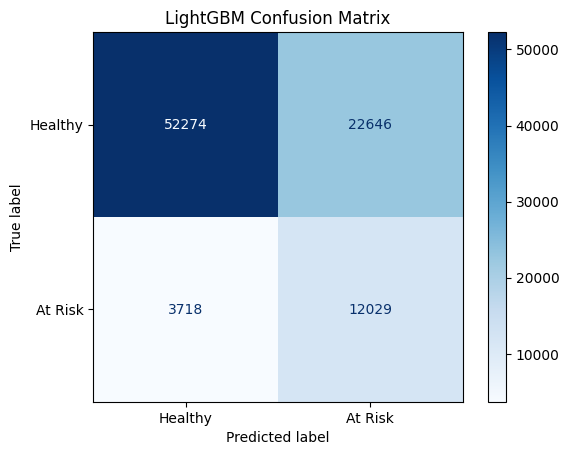

LightGBM ROC-AUC Score: 0.8058
All CatBoost and LightGBM models and evaluation logs saved successfully!


In [10]:
y_prob_lgb = lgb_model.predict_proba(xtest_df1)[:, 1]
y_pred_lgb = (y_prob_lgb >= 0.5).astype(int)

print("--- LightGBM Classification Report ---")
print(classification_report(
    ytest_df1,
    y_pred_lgb,
    target_names=["Healthy", "At Risk"],
    zero_division=0
))

cm_lgb = confusion_matrix(ytest_df1, y_pred_lgb)
ConfusionMatrixDisplay(
    confusion_matrix=cm_lgb,
    display_labels=["Healthy", "At Risk"]
).plot(cmap=plt.cm.Blues)

plt.title("LightGBM Confusion Matrix")
plt.savefig(ASSET_DIR / "confusion_matrix_lightgbm.png", dpi=300, bbox_inches="tight")
plt.show()

# Save LightGBM model and evaluation metrics
joblib.dump(lgb_model, MODEL_DIR / "lightgbm_model.pkl")

lgb_metrics = classification_report(
    ytest_df1, y_pred_lgb, target_names=["Healthy", "At Risk"], output_dict=True
)
with open(MODEL_DIR / "model_lightgbm_evaluations.json", "w") as f:
    json.dump(lgb_metrics, f, indent=4)

print(f"LightGBM ROC-AUC Score: {roc_auc_score(ytest_df1, y_prob_lgb):.4f}")
print("All CatBoost and LightGBM models and evaluation logs saved successfully!")